# Milestone 2: Data Audit and Baseline

In [ ]:
import pandas as pd
import numpy as np

#load core tables
apps = pd.read_csv('../data/applications.csv', low_memory=False)
labels = pd.read_csv('../data/review_labels.csv')

#merge apps and labels
df = apps.merge(labels, on='appid', how='inner')

#Load the genres
app_genres = pd.read_csv('../data/application_genres.csv')
genres = pd.read_csv('../data/genres.csv')

# We merge using 'genre_id' from the left and 'id' from the right
genre_merged = app_genres.merge(genres, left_on='genre_id', right_on='id', how='inner')

# rename 'name' to 'genre_name' so the rest of the pipeline works
genre_merged = genre_merged.rename(columns={'name': 'genre_name'})

# Multi-hot encode genres
genre_dummies = pd.get_dummies(genre_merged, columns=['genre_name'])
genre_features = genre_dummies.groupby('appid').sum().reset_index()

#Final merge
df = df.merge(genre_features, on='appid', how='left')
print("Final dataset shape:", df.shape)

Final dataset shape: (117311, 190)


## 1. Data Audit
Before modeling, we inspect the dataset for missing values, duplicates, and class imbalance.

In [3]:
print("--- Missing Values (Top 10) ---")
print(df.isna().sum().sort_values(ascending=False).head(10))

print("\n--- Duplicates ---")
print("Duplicate rows:", df.duplicated().sum())

print("\n--- Target Distribution ---")
print(df['rating_label'].value_counts(normalize=True).round(3))

--- Missing Values (Top 10) ---
metacritic_score         112857
recommendations_total     94866
mat_pc_graphics_rec       66456
mat_achievement_count     65679
mat_pc_processor_rec      64117
mat_pc_memory_rec         63841
mat_pc_os_rec             62102
mat_pc_graphics_min       25450
mat_pc_memory_min         17723
mat_pc_processor_min      17395
dtype: int64

--- Duplicates ---
Duplicate rows: 0

--- Target Distribution ---
rating_label
Mostly Positive    0.642
Mostly Negative    0.169
Mixed              0.166
Very Positive      0.023
Name: proportion, dtype: float64


## 2. Train/Test Split
We split the data before any scaling or imputation to prevent data leakage. We use `stratify=y` to ensure the 2.3% minority class ("Very Positive") is represented in both the training and test sets.

In [ ]:
from sklearn.model_selection import train_test_split

# Drop leakage columns (things derived from the target) and useless identifiers
cols_to_drop = [
    'appid', 'name', 'rating_label', 'positive_count', 'total_count', 'positive_pct',
    'recommendations_total', 'metacritic_score', 'header_image', 'background',
    'short_description', 'created_at', 'updated_at', 'supported_languages'
]

# Separate features (X) and target (y)
X = df.drop(columns=cols_to_drop, errors='ignore')
y = df['rating_label']

# Split the data (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set: {X_train.shape}")
print(f"Testing set: {X_test.shape}")

Training set: (93848, 176)
Testing set: (23463, 176)


## 3. Preprocessing Pipeline
We use a `ColumnTransformer` to apply different preprocessing to numeric and categorical columns. This ensures the imputer and scaler only learn from the training data.

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Automatically identify numeric and categorical columns
numeric_cols = X_train.select_dtypes(include=['int64', 'float64', 'bool']).columns.tolist()
categorical_cols = X_train.select_dtypes(include=['object']).columns.tolist()

# Numeric pipeline: fill missing with median, then scale
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical pipeline: fill missing with a placeholder, then one-hot encode
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine them
preprocessor = ColumnTransformer([
    ('num', num_pipeline, numeric_cols),
    ('cat', cat_pipeline, categorical_cols)
])

print("Pipeline built successfully.")

Pipeline built successfully.


/tmp/ipykernel_54236/958899829.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X_train.select_dtypes(include=['object']).columns.tolist()


## 4. Baseline Model
We train a Logistic Regression model with `class_weight='balanced'` to account for the severe class imbalance. The model is fitted inside the pipeline to ensure the preprocessing is applied correctly.

--- Baseline Model Performance ---
Accuracy: 0.4754
Macro F1: 0.3237


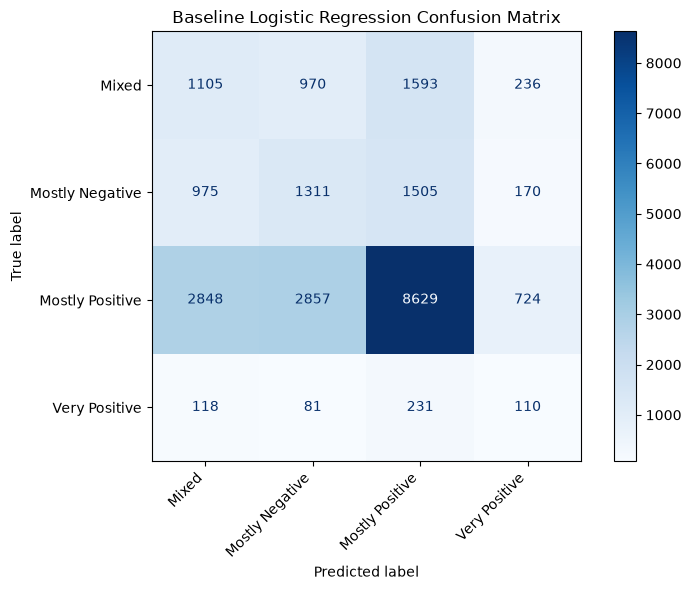

In [7]:
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay

# Build the final pipeline including preprocessing and the classifier
baseline_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
])

# Train the model on the training data
baseline_model.fit(X_train, y_train)

# Predict on the protected test set
y_pred = baseline_model.predict(X_test)

# Evaluate and print the metrics
print("--- Baseline Model Performance ---")
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"Macro F1: {f1_score(y_test, y_pred, average='macro'):.4f}")

# Generate and display the labeled confusion matrix
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, 
    y_pred, 
    display_labels=baseline_model.classes_, 
    cmap='Blues', 
    ax=ax
)

# Format the plot for readability
plt.title("Baseline Logistic Regression Confusion Matrix")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

*Note on results:* The baseline model achieves an Accuracy of 47.5% and a Macro F1 score of 0.324. Because we applied `class_weight='balanced'`, the model prioritizes minority classes, which lowers raw accuracy but improves fairness. 

The confusion matrix reveals that the model struggles most with the "Very Positive" class (only 110 correct out of ~540), frequently confusing it with "Mostly Positive". This highlights the challenge of the 2.3% minority class and establishes a strong baseline for Milestone 3's model comparison.